In [1]:
%matplotlib inline

from IPython.display import Markdown

from src.algorithm.FixedRoutePolicy import FixedRoutePolicy
from src.algorithm.NearestUnservedPolicy import NearestUnservedPolicy
from src.algorithm.SkipStopFixedRoutePolicy import SkipStopFixedRoutePolicy
from src.experiment import (
    compare_policies,
    plot_kpi_bars,
    plot_occupancy,
    plot_wait_distribution,
    run_trial,
    show_animations,
    summarize_comparison,
)
from src.map.PlanarMapProvider import PlanarMapProvider
from src.map.graph import PlanarStreetGraph

In [2]:
MAP_SEED = 42

graph = PlanarStreetGraph.generate(
    n_seeds=20,
    bounds=(0.0, 0.0, 5000.0, 5000.0),
    seed=MAP_SEED,
    stop_density=0.4,
)

provider = PlanarMapProvider(graph)
print(f"{len(provider.get_stops())} bus stops on this map")

20 bus stops on this map


In [3]:
N_TRIALS = 2000
BASE_SEED = 0

summary = summarize_comparison(
    policies=[
        ("Fixed route",      lambda g: FixedRoutePolicy(g)),
        ("Fixed route w/ skip", lambda g: SkipStopFixedRoutePolicy(g)),
    ],
    graph=graph,
    n_trials=N_TRIALS,
    base_seed=BASE_SEED,
    # Forwarded to run_trial:
    max_requests=200,
    capacity=16,
)
Markdown(summary.markdown)

Fixed route        :   0%|          | 0/2000 [00:00<?, ?it/s]

Fixed route w/ skip:   0%|          | 0/2000 [00:00<?, ?it/s]

| Property | Fixed route | Fixed route w/ skip |
| --- | --- | --- |
| Fulfilled requests | 198.7 (±0.0%) | 199.9 (±0.0%) |
| Cancelled requests | 0.0 (±0.0%) | 0.0 (±0.0%) |
| Mean wait time | 9048.2 s (±0.3%) | 8683.2 s (±0.3%) |
| P90 wait time | 18217.0 s (±0.3%) | 17347.8 s (±0.3%) |
| Mean ride time | 2233.0 s (±0.2%) | 2097.2 s (±0.2%) |
| Fulfillment rate | 100.0 % (±0.0%) | 100.0 % (±0.0%) |
| Throughput | 0.3 req/min (±0.2%) | 0.4 req/min (±0.2%) |
| Tick snapshots | 35296.5 (±0.1%) | 33290.3 (±0.2%) |
| Fulfilled (wait samples) | 198.7 (±0.0%) | 199.9 (±0.0%) |
| Min wait time | 63.6 s (±4.1%) | 82.1 s (±4.3%) |
| Max wait time | 24316.5 s (±0.4%) | 23071.3 s (±0.4%) |
| Min ride time | 33.9 s (±3.9%) | 33.6 s (±3.9%) |
| Max ride time | 4444.2 s (±0.0%) | 4391.5 s (±0.2%) |

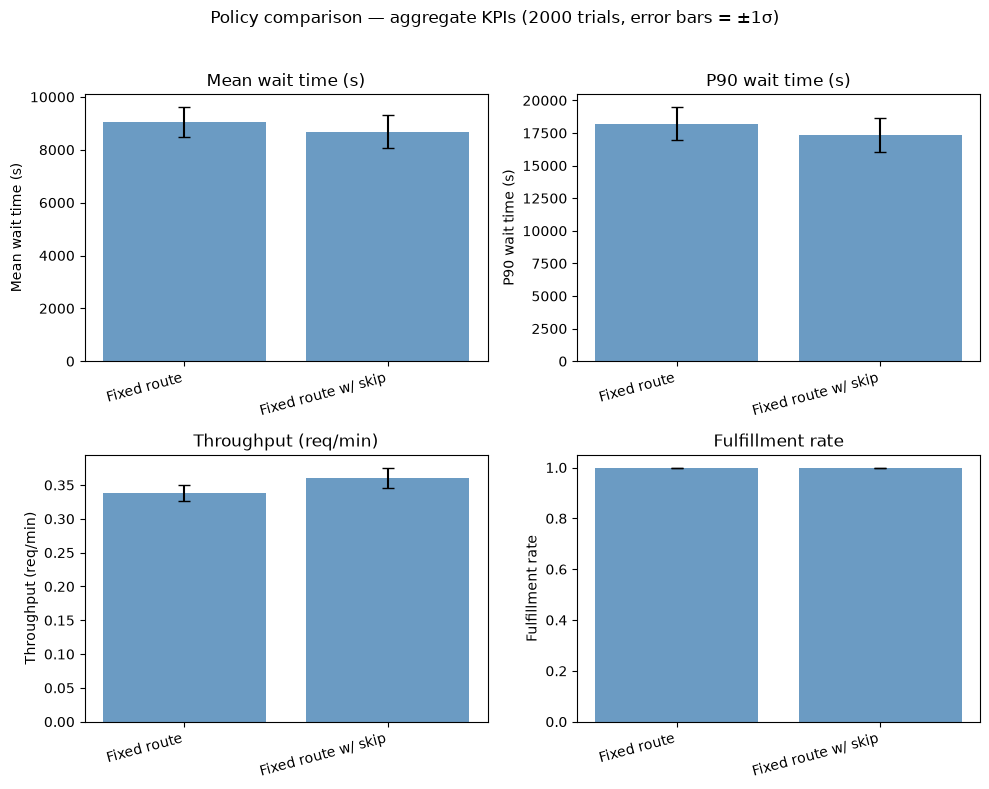

In [4]:
fig = plot_kpi_bars(
    summary.results,
    fields=["mean_wait_time", "p90_wait_time", "throughput", "fulfillment_rate"],
    title=f"Policy comparison — aggregate KPIs "
          f"({N_TRIALS} trials, error bars = ±1σ)",
)

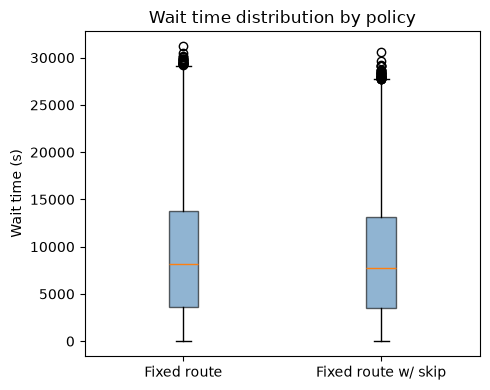

In [5]:
fig = plot_wait_distribution(summary.results)

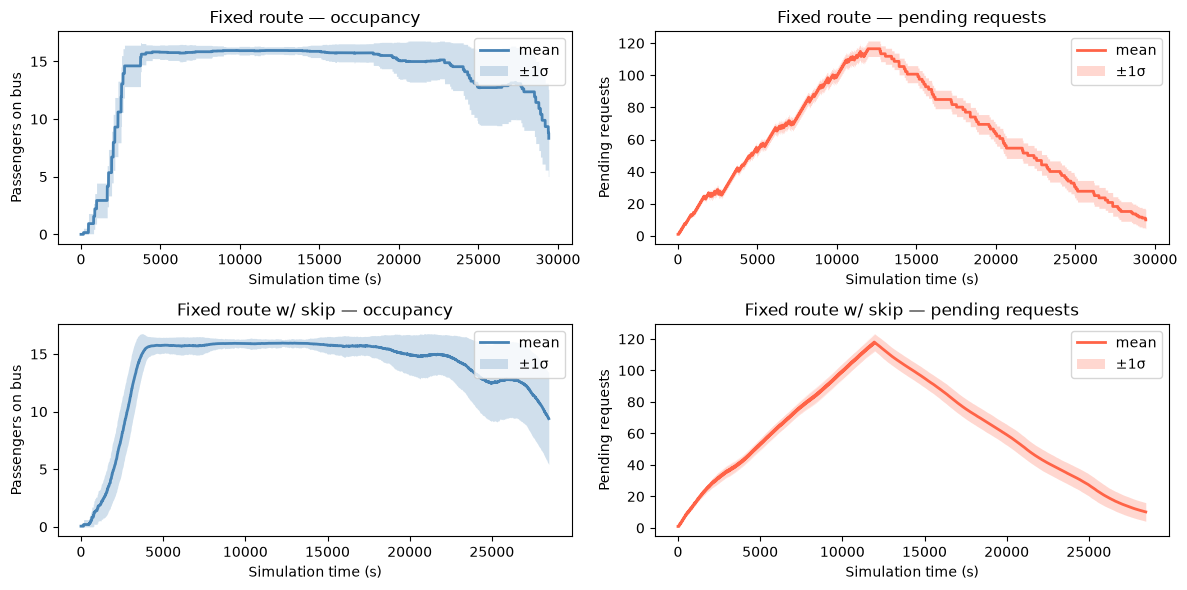

In [6]:
fig = plot_occupancy(summary.results)